# Oil Spill Dataset Exploration

This notebook explores SAR images from three classes:
- Oil Spill
- Look-alike
- No Oil

We will examine image dimensions, data types, radar channels, pixel values, and segmentation masks.

## 1. Dataset Inspection

We inspected sample TIFF images on the MBZUAI HPC.

### Oil Spill Image
- Dimensions: 2048 × 2048
- Channels: 2 (VV and VH)
- Data type: float32

### Segmentation Mask
- Dimensions: 2048 × 2048
- Data type: uint8
- Pixel values: 0 and 1

The image and mask have matching dimensions.

The mask uses 1 to identify labeled oil-spill regions and 0 for the remaining pixels.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tifffile

print("Python is ready!")

Python is ready!


In [2]:
from pathlib import Path

folder = Path.home() / "oil_spill_samples"

image = tifffile.imread(folder / "01162.tif")
mask = tifffile.imread(folder / "oil_mask_01162.tif")

print("Image shape:", image.shape)
print("Image type:", image.dtype)
print("Mask shape:", mask.shape)
print("Mask values:", np.unique(mask))

Image shape: (2048, 2048, 2)
Image type: float32
Mask shape: (2048, 2048)
Mask values: [0 1]


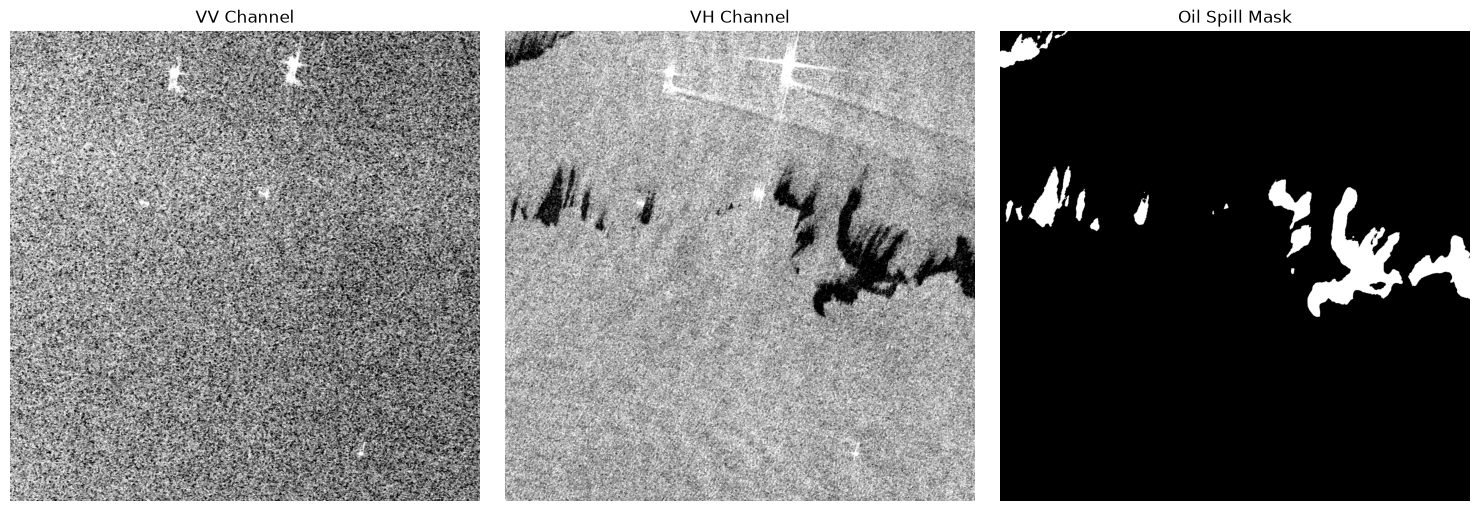

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image[:, :, 0], cmap="gray", vmin=np.percentile(image[:, :, 0], 2), vmax=np.percentile(image[:, :, 0], 98))
axes[0].set_title("VV Channel")

axes[1].imshow(image[:, :, 1], cmap="gray", vmin=np.percentile(image[:, :, 1], 2), vmax=np.percentile(image[:, :, 1], 98))
axes[1].set_title("VH Channel")

axes[2].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Oil Spill Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
for i, name in enumerate(["VV", "VH"]):
    channel = image[:, :, i]
    print(name)
    print("Minimum:", np.nanmin(channel))
    print("Maximum:", np.nanmax(channel))
    print("Mean:", np.nanmean(channel))
    print("Invalid values:", np.sum(~np.isfinite(channel)))
    print()

VV
Minimum: -46.44197
Maximum: 1.5661435
Mean: -34.01896
Invalid values: 0

VH
Minimum: -38.071007
Maximum: 23.442541
Mean: -23.535095
Invalid values: 0



### 2. Radar Channel Analysis

We examined the VV and VH radar channels of one oil-spill image.

- VV values ranged from approximately -46.44 to 1.57.
- VH values ranged from approximately -38.07 to 23.44.
- Neither channel contained invalid values.
- The oil spill was easier to see in the VH channel for this sample.
- The segmentation mask appeared to match the dark regions in VH.

These observations are based on one image, so we need to examine more samples before drawing conclusions.

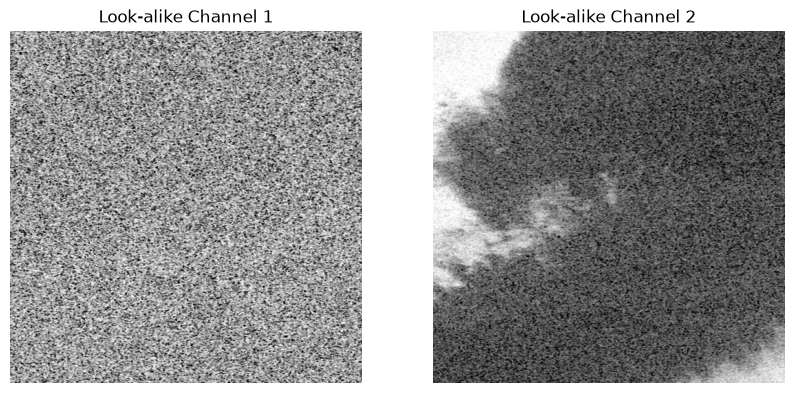

In [5]:
from PIL import Image

folder = Path.home() / "AI2210-Oil-Spill/data/samples"

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for i in range(2):
    img = Image.open(folder / f"channel{i+1}.png")
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Look-alike Channel {i+1}")
    axes[i].axis("off")

plt.show()

### 3. Look-Alike Image Analysis

We examined a look-alike sample using two radar channels.

- Channel 1 appeared mostly grainy.
- Channel 2 showed a large dark region.
- This dark region could be mistaken for an oil spill.
- This shows why distinguishing real oil spills from look-alikes may be difficult.

We need to examine more samples to understand these differences better.

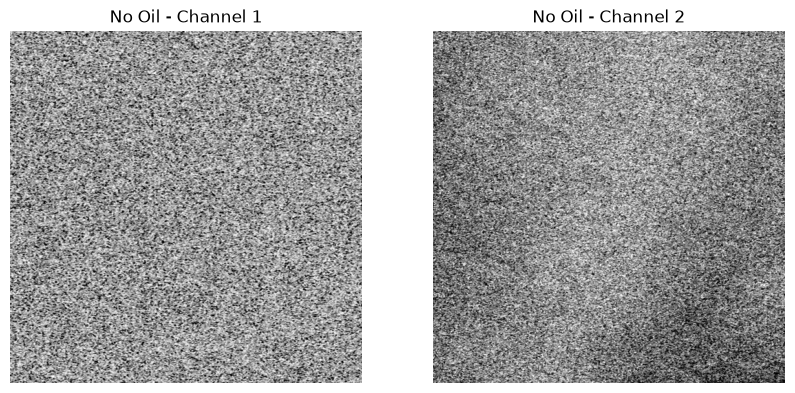

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for i in range(2):
    img = Image.open(folder / f"no_oil_channel{i+1}.png")
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"No Oil - Channel {i+1}")
    axes[i].axis("off")

plt.show()

### 4. No-Oil Image Analysis

We examined a no-oil sample using two radar channels.

- Channel 1 appeared mostly grainy.
- Channel 2 showed some darker areas.
- There were no obvious oil-spill shapes in this example.
- Compared with the oil-spill and look-alike samples, this image appeared more uniform.

These observations are based on one sample from each class.

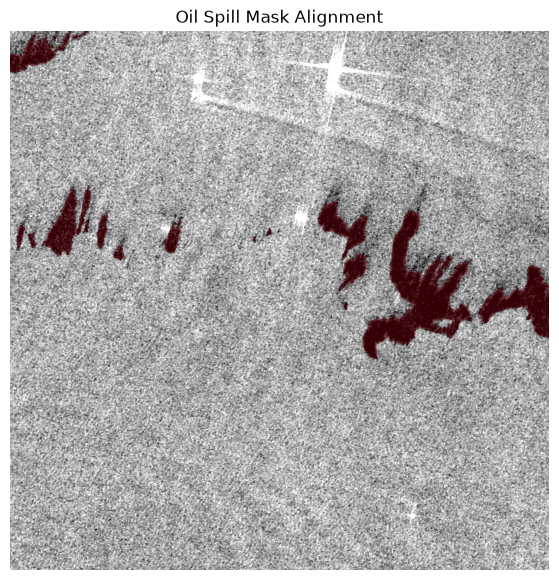

In [7]:
plt.figure(figsize=(7, 7))

plt.imshow(image[:, :, 1], cmap="gray",
           vmin=np.percentile(image[:, :, 1], 2),
           vmax=np.percentile(image[:, :, 1], 98))

plt.imshow(np.ma.masked_where(mask == 0, mask),
           cmap="Reds", alpha=0.5, vmin=0, vmax=1)

plt.title("Oil Spill Mask Alignment")
plt.axis("off")
plt.show()

In [ ]:
### 5. Segmentation Mask Alignment

We placed the oil-spill mask over the VH radar image.

- The red areas represent the labeled oil-spill regions.
- The mask follows the dark shapes in the radar image.
- The image and mask have matching dimensions.
- No obvious alignment problems were found in this sample.

This suggests that the mask is correctly aligned with its corresponding image.

In [8]:
image2 = tifffile.imread(folder / "00000.tif")
mask2 = tifffile.imread(folder / "mask_00000.tif")

print("Image:", image2.shape)
print("Mask:", mask2.shape)
print("Mask values:", np.unique(mask2))

Image: (2048, 2048, 2)
Mask: (2048, 2048)
Mask values: [0 1]


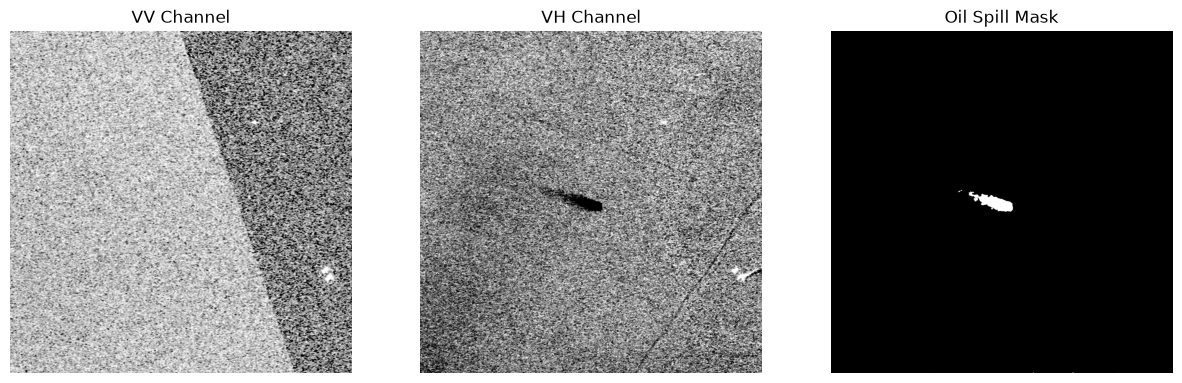

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, name in enumerate(["VV", "VH"]):
    channel = image2[:, :, i]
    axes[i].imshow(channel, cmap="gray",
                   vmin=np.percentile(channel, 2),
                   vmax=np.percentile(channel, 98))
    axes[i].set_title(name + " Channel")

axes[2].imshow(mask2, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Oil Spill Mask")

for ax in axes:
    ax.axis("off")

plt.show()

In [10]:
for name, m in [("01162", mask), ("00000", mask2)]:
    percentage = np.mean(m == 1) * 100
    print(f"{name}: {percentage:.2f}% oil")

01162: 4.54% oil
00000: 0.35% oil


### Class Imbalance Findings

We compared two oil-spill images.

- Image 01162 contained 4.54% oil pixels.
- Image 00000 contained only 0.35% oil pixels.
- Most pixels in both images were non-oil.
- Oil spills can have very different sizes.

This means pixel accuracy alone may not be a good way to evaluate our model. We should also use IoU or Dice score.